# Rigid-Bar Network Shear Modulus G(z)



| File | Produced by | Columns (tab-separated) |
|---|---|---|
| `G_curvature_vs_z.dat` | `gmod` mode; one row per (realization, dgamma) | `z  Nc  dgamma  G_fd  Gamma0  iters  residual_err` |
| `<network>_nve.dat` | `nve` mode; one file per invocation | 3 `#`-comment header lines, then `step  KE  max_bar_err  max_vel_constraint  sigma_xy` |

In [1]:
import glob
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({
    "figure.dpi": 100,
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

In [2]:
DATA_DIR = Path(".")
FIGURE_DIR = Path("./figures")
SAVE_FIGURES = True
FIGURE_DPI = 300
# The C code reports G_fd for several dgamma (strain-step) values per realization. This only *selects* which already-computed dgamma is used
# for the headline G(z) curve (Figure 1); it's a display choice, not a new calculation.
GMOD_DGAMMA_SELECT = "min"
#min->1e-6
#max->1e-3

# Minimum number of realizations required at a given (z, dgamma) before
# Section 6 stops flagging it as a thin ensemble. 0 disables the check.
MIN_N_WARN = 5

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

## Detect Output Files

In [3]:
gmod_path = DATA_DIR / "G_curvature_vs_z.dat"
nve_paths = sorted(glob.glob(str(DATA_DIR / "*_nve.dat")))
have_gmod = gmod_path.exists()
have_nve = len(nve_paths) > 0
print(f"GMOD   G_curvature_vs_z.dat : {'found' if have_gmod else 'NOT FOUND'}  ({gmod_path})")
print(f"NVE    *_nve.dat            : {len(nve_paths)} file(s)")
for p in nve_paths:
    print(f"  - {p}")

GMOD   G_curvature_vs_z.dat : found  (G_curvature_vs_z.dat)
NVE    *_nve.dat            : 6 file(s)
  - floppy_network_N1600_z2.100_s00000_nve.dat
  - floppy_network_N1600_z2.400_s00000_nve.dat
  - floppy_network_N1600_z2.800_s00000_nve.dat
  - floppy_network_N1600_z3.200_s00000_nve.dat
  - floppy_network_N1600_z3.600_s00000_nve.dat
  - floppy_network_N1600_z3.900_s00000_nve.dat


## Load GMOD Results

In [4]:
GMOD_COLUMNS = ["z", "Nc", "dgamma", "G_fd", "Gamma0", "iters", "residual_err"]

def load_gmod(path):
    """Load G_curvature_vs_z.dat: one row per (realization, dgamma) pair."""
    df = pd.read_csv(path, sep="\t")
    missing = set(GMOD_COLUMNS) - set(df.columns)
    if missing:
        raise ValueError(f"{path} is missing expected columns: {missing}")
    return df.sort_values(["z", "dgamma"]).reset_index(drop=True)


df_gmod = None
if have_gmod:
    df_gmod = load_gmod(gmod_path)
    print(f"Loaded {len(df_gmod)} row(s): {df_gmod['z'].nunique()} distinct z, "
          f"{df_gmod['dgamma'].nunique()} distinct dgamma")
    display(df_gmod.head(80))
else:
    print("G_curvature_vs_z.dat not found -- skipping GMOD analysis.")

Loaded 24 row(s): 6 distinct z, 4 distinct dgamma


,z,Nc,dgamma,G_fd,Gamma0,iters,residual_err
0,2.1,1680,0.000001,-0.010361,-0.000985,1,7.790000e-13
1,2.1,1680,0.000010,-0.010357,-0.000985,2,5.793000e-15
2,2.1,1680,0.000100,-0.010357,-0.000985,2,5.540000e-15
3,2.1,1680,0.001000,-0.010358,-0.000985,2,1.321000e-13
4,2.4,1920,0.000001,-0.057748,0.002180,2,5.980000e-15
5,2.4,1920,0.000010,-0.057797,0.002180,2,5.297000e-15
6,2.4,1920,0.000100,-0.057811,0.002180,2,6.417000e-15
7,2.4,1920,0.001000,-0.057902,0.002180,3,5.816000e-15
8,2.8,2240,0.000001,-0.076562,0.000279,2,5.831000e-15
9,2.8,2240,0.000010,-0.076573,0.000279,2,5.896000e-15


## Load NVE Diagnostics

In [5]:
NVE_COLUMNS = ["step", "KE", "max_bar_err", "max_vel_constraint", "sigma_xy"]

def load_nve(path):
    """Load one *_nve.dat file (3 '#' header lines, then tab-separated data)."""
    return pd.read_csv(path, sep="\t", comment="#", header=None, names=NVE_COLUMNS)


nve_runs = {}
for p in nve_paths:
    nve_runs[Path(p).name] = load_nve(p)
    print(f"Loaded {len(nve_runs[Path(p).name])} row(s) from {Path(p).name}")

if not nve_paths:
    print("No *_nve.dat files found -- skipping NVE diagnostics.")

Loaded 101 row(s) from floppy_network_N1600_z2.100_s00000_nve.dat
Loaded 101 row(s) from floppy_network_N1600_z2.400_s00000_nve.dat
Loaded 101 row(s) from floppy_network_N1600_z2.800_s00000_nve.dat
Loaded 101 row(s) from floppy_network_N1600_z3.200_s00000_nve.dat
Loaded 101 row(s) from floppy_network_N1600_z3.600_s00000_nve.dat
Loaded 101 row(s) from floppy_network_N1600_z3.900_s00000_nve.dat


## Ensemble Statistics

In [6]:
def compute_statistics(df, group_cols, value_col, min_n_warn=5):
    """Group by group_cols and compute mean / std / SEM of value_col.
    The only statistic used anywhere in this notebook."""
    stats = (
        df.groupby(group_cols)[value_col]
        .agg(mean="mean", std="std", n="count")
        .reset_index()
    )
    stats["std"] = stats["std"].fillna(0.0)
    stats["sem"] = stats["std"] / np.sqrt(stats["n"])

    thin = stats[stats["n"] < min_n_warn]
    if min_n_warn > 0 and not thin.empty:
        cols = group_cols if isinstance(group_cols, list) else [group_cols]
        print(f"WARNING: {len(thin)} group(s) have fewer than {min_n_warn} "
              f"realizations -- treat as unreliable until more runs are added:")
        display(thin[cols + ["n"]])

    return stats


gmod_stats = None
if df_gmod is not None:
    gmod_stats = compute_statistics(df_gmod, ["z", "dgamma"], "G_fd", min_n_warn=MIN_N_WARN)
    print("G_fd(z, dgamma) ensemble statistics:")
    display(gmod_stats.head(10))

    # Simple convergence check: what fraction of relaxToConstraintManifold()
    # calls failed to converge (iters == -1) at each z? Worth watching as z
    # approaches z_c = 4, where the Gram matrix N gets ill-conditioned.
    fail_rate = (
        df_gmod.assign(failed=df_gmod["iters"] == -1)
        .groupby("z")["failed"].mean()
        .rename("fail_rate")
        .reset_index()
    )
    print("\nFraction of (realization, dgamma) pairs with iters == -1, by z:")
    display(fail_rate)

,z,dgamma,n
0,2.1,0.000001,1
1,2.1,0.000010,1
2,2.1,0.000100,1
3,2.1,0.001000,1
4,2.4,0.000001,1
5,2.4,0.000010,1
6,2.4,0.000100,1
7,2.4,0.001000,1
8,2.8,0.000001,1
9,2.8,0.000010,1


G_fd(z, dgamma) ensemble statistics:


,z,dgamma,mean,std,n,sem
0,2.1,0.000001,-0.010361,0.0,1,0.0
1,2.1,0.000010,-0.010357,0.0,1,0.0
2,2.1,0.000100,-0.010357,0.0,1,0.0
3,2.1,0.001000,-0.010358,0.0,1,0.0
4,2.4,0.000001,-0.057748,0.0,1,0.0
5,2.4,0.000010,-0.057797,0.0,1,0.0
6,2.4,0.000100,-0.057811,0.0,1,0.0
7,2.4,0.001000,-0.057902,0.0,1,0.0
8,2.8,0.000001,-0.076562,0.0,1,0.0
9,2.8,0.000010,-0.076573,0.0,1,0.0



Fraction of (realization, dgamma) pairs with iters == -1, by z:


,z,fail_rate
0,2.1,0.0
1,2.4,0.0
2,2.8,0.0
3,3.2,0.0
4,3.6,0.0
5,3.9,0.0


## Figures

In [7]:
_saved_figures = []

def save_figure(fig, name):
    """Save fig to FIGURE_DIR/<name>.png if SAVE_FIGURES is True."""
    if not SAVE_FIGURES:
        return None
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    out_path = FIGURE_DIR / f"{name}.png"
    fig.savefig(out_path, dpi=FIGURE_DPI, bbox_inches="tight")
    _saved_figures.append(out_path)
    print(f"Saved figure -> {out_path}")
    return out_path

### Figure 1 — Nonlinear shear modulus $G(z)$

Saved figure -> figures/fig1_G_vs_z.png


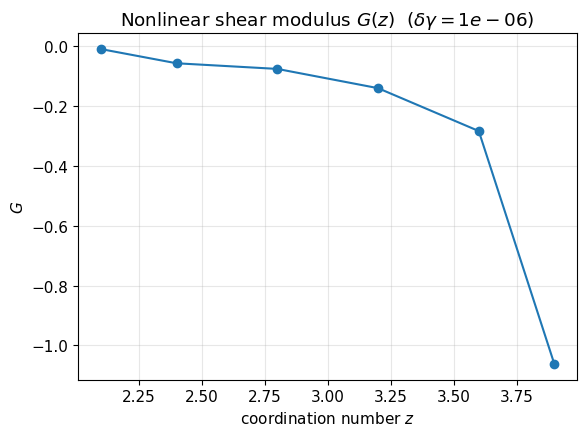

In [8]:
def select_gmod_curve(gmod_stats, select):
    """Pick one G_fd(z) curve out of the (z, dgamma) stats table.
    Only selects among dgamma values the C code already computed."""
    if select == "min":
        dgamma_val = gmod_stats["dgamma"].min()
    elif select == "max":
        dgamma_val = gmod_stats["dgamma"].max()
    else:
        dgamma_val = float(select)
    sub = (
        gmod_stats[np.isclose(gmod_stats["dgamma"], dgamma_val)]
        .sort_values("z")
        .reset_index(drop=True)
    )
    return sub, dgamma_val


fig1 = None
if gmod_stats is not None:
    gmod_curve, dgamma_used = select_gmod_curve(gmod_stats, GMOD_DGAMMA_SELECT)
    fig1, ax1 = plt.subplots(figsize=(6, 4.5))
    ax1.errorbar(gmod_curve["z"], gmod_curve["mean"], yerr=gmod_curve["sem"],
                 marker="o", linestyle="-", capsize=3)
    ax1.set_xlabel(r"coordination number $z$")
    ax1.set_ylabel(r"$G$")
    ax1.set_title(rf"Nonlinear shear modulus $G(z)$  ($\delta\gamma={dgamma_used:.2g}$)")
    fig1.tight_layout()
    save_figure(fig1, "fig1_G_vs_z")
    plt.show()
else:
    print("No GMOD data available; skipping Figure 1.")

### Figure 2 — Finite-difference convergence: does $G_{\rm fd}$ plateau as $\delta\gamma \to 0$?

Saved figure -> figures/fig2_dgamma_convergence.png


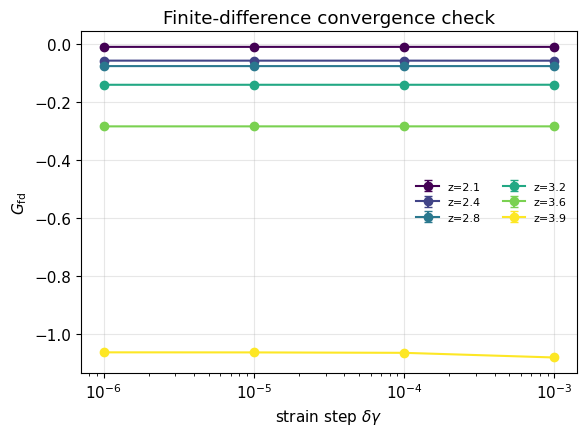

In [9]:
fig2 = None
if gmod_stats is not None and gmod_stats["dgamma"].nunique() > 1:
    fig2, ax2 = plt.subplots(figsize=(6, 4.5))
    z_values = sorted(gmod_stats["z"].unique())
    colors = plt.cm.viridis(np.linspace(0, 1, len(z_values)))
    for z_val, color in zip(z_values, colors):
        sub = gmod_stats[gmod_stats["z"] == z_val].sort_values("dgamma")
        ax2.errorbar(sub["dgamma"], sub["mean"], yerr=sub["sem"],
                     marker="o", color=color, capsize=3, label=f"z={z_val:.3g}")
    ax2.set_xscale("log")
    ax2.set_xlabel(r"strain step $\delta\gamma$")
    ax2.set_ylabel(r"$G_{\rm fd}$")
    ax2.set_title("Finite-difference convergence check")
    ax2.legend(frameon=False, fontsize=8, ncol=2)
    fig2.tight_layout()
    save_figure(fig2, "fig2_dgamma_convergence")
    plt.show()
else:
    print("Fewer than 2 dgamma values available; skipping Figure 2.")

### Figure 3 — NVE diagnostics: energy and constraint drift over a run

Saved figure -> figures/fig3_nve_diagnostics.png


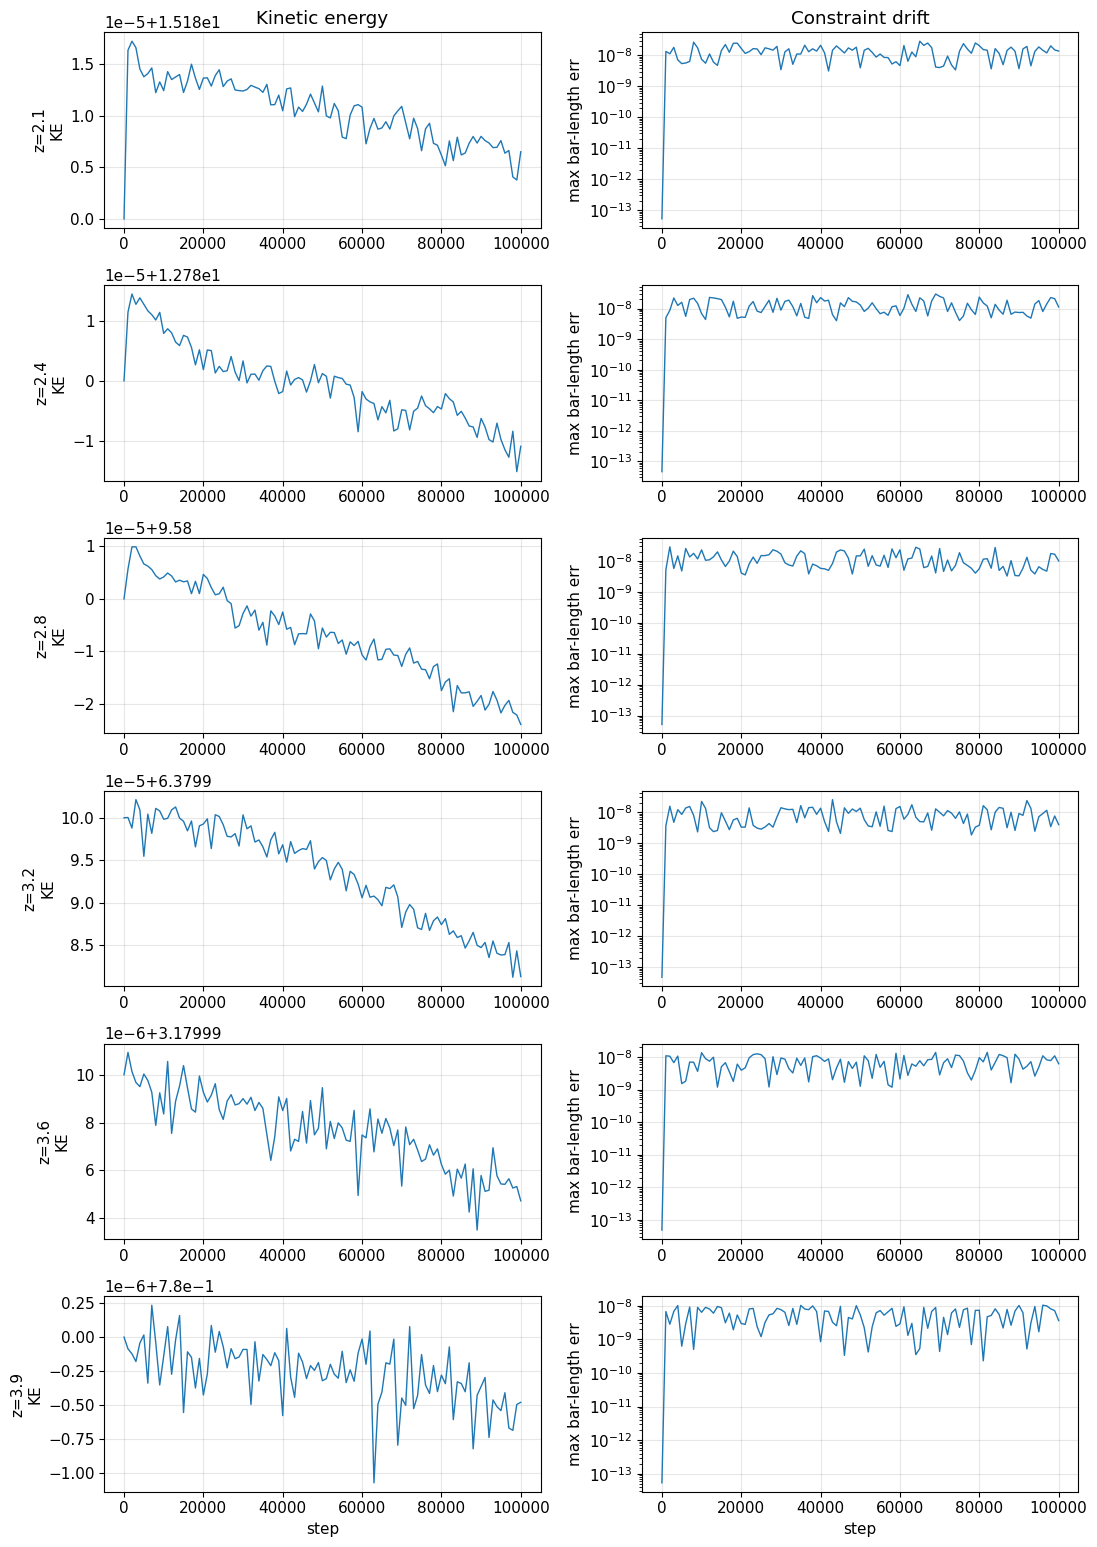

In [10]:
NVE_COLUMNS = ["step", "KE", "max_bar_err", "max_vel_constraint", "sigma_xy"]

def load_nve(path):
    """z comes from the file's own header, not the filename -- yours got
    their '.' turned into '_' on upload, filenames aren't reliable."""
    with open(path) as f:
        header = f.readline()
    m = re.search(r"z=([0-9.]+)", header)
    z = float(m.group(1)) if m else float("nan")
    df = pd.read_csv(path, sep="\t", comment="#", header=None, names=NVE_COLUMNS)
    return df, z

nve_runs, nve_z = {}, {}
for p in nve_paths:
    name = Path(p).name
    nve_runs[name], nve_z[name] = load_nve(p)

fig3 = None
if nve_runs:
    z_groups = {}
    for name in nve_runs:
        z_groups.setdefault(nve_z[name], []).append(name)
    z_values = sorted(z_groups)

    fig3, axes = plt.subplots(len(z_values), 2, figsize=(11, 2.6 * len(z_values)), squeeze=False)
    for row, z in enumerate(z_values):
        axKE, axErr = axes[row]
        for name in z_groups[z]:
            df = nve_runs[name]
            axKE.plot(df["step"], df["KE"], linewidth=1, label=name)
            axErr.semilogy(df["step"], df["max_bar_err"], linewidth=1, label=name)
        axKE.set_ylabel(f"z={z:g}\nKE")
        axErr.set_ylabel("max bar-length err")
        if len(z_groups[z]) > 1:
            axKE.legend(frameon=False, fontsize=6)
        if row == 0:
            axKE.set_title("Kinetic energy")
            axErr.set_title("Constraint drift")
    axes[-1, 0].set_xlabel("step")
    axes[-1, 1].set_xlabel("step")
    fig3.tight_layout()
    save_figure(fig3, "fig3_nve_diagnostics")
    plt.show()